# Partial observations and recurrent control

Official MiniGrid local views create a different information problem from the full-map experiments. The agent receives a 7×7 symbolic view and direction only, with sparse official rewards. The animation shows the global environment for the reader; it is not the policy input.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
torch.set_num_threads(1)


def read(path):
    return json.loads((ROOT / path).read_text())


%matplotlib inline

Observed view shape: (151,) ; only local codes and direction


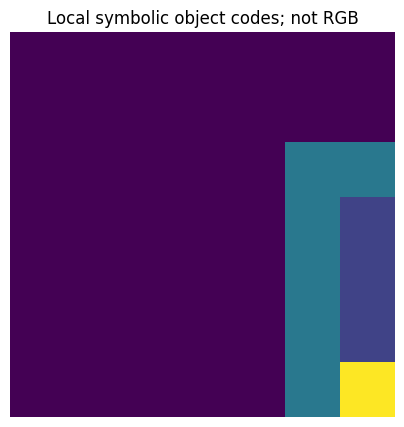

In [2]:
from decision_lab.modern import environment

case = {"env": "MiniGrid-DoorKey-6x6-v0", "algorithm": "RecurrentPPO", "profile": "partial"}
env = environment(case)
obs, _ = env.reset(seed=300000)
assert obs.shape == (151,) and np.isfinite(obs).all()
print("Observed view shape:", obs.shape, "; only local codes and direction")
plt.figure(figsize=(5, 5))
plt.imshow(env.unwrapped.gen_obs()["image"][:, :, 0])
plt.title("Local symbolic object codes; not RGB")
plt.axis("off")
plt.show()
env.close()

## Stateful deployment

Reset both hidden and cell state at each episode boundary; retain them within the episode. The portable actor contains the LSTM and actor network, with no critic, replay buffer or private training checkpoint.

In [3]:
from decision_lab.modern import evaluate
from decision_lab.modern_deployment import load

actor = load(ROOT / "assets/modern_actors/MiniGrid-DoorKey-6x6-v0_RecurrentPPO_partial_0.npz")
first, memory = actor.predict(obs, episode_start=np.array([True]))
_, next_memory = actor.predict(obs, state=memory, episode_start=np.array([False]))
reset, reset_memory = actor.predict(obs, state=next_memory, episode_start=np.array([True]))
assert first == reset
for a, b in zip(memory, reset_memory):
    np.testing.assert_array_equal(a, b)
fresh = evaluate(actor, case, [300000, 300001])
source = np.load(
    ROOT / "assets/source_data/modern/MiniGrid-DoorKey-6x6-v0_RecurrentPPO_partial_0.npz",
    allow_pickle=False,
)
np.testing.assert_array_equal(fresh["returns"], source["returns"][:2])
print(fresh["returns"])

[0.965  0.9675]


return             success          
                                          mean       std      mean       std
task                    method                                              
MiniGrid-DoorKey-6x6-v0 PPO           0.937033  0.020573  0.966667  0.020817
                        RecurrentPPO  0.969142  0.000411  1.000000  0.000000
MiniGrid-Empty-8x8-v0   PPO           0.960156  0.002030  1.000000  0.000000
                        RecurrentPPO  0.957812  0.000000  1.000000  0.000000

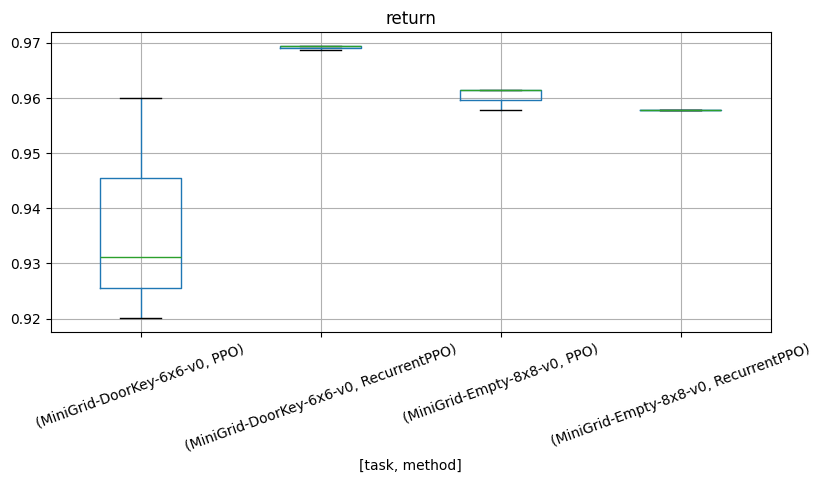

In [4]:
rows = []
for path in (ROOT / "results/reference/modern").glob("MiniGrid*/*/metrics.json"):
    m = json.loads(path.read_text())
    rows.append(
        {
            "task": m["env"],
            "method": m["algorithm"],
            "seed": m["seed"],
            "return": m["test"]["mean"],
            "success": m["success_fraction"],
        }
    )
table = pd.DataFrame(rows)
assert len(table) == 12
display(table.groupby(["task", "method"])[["return", "success"]].agg(["mean", "std"]))
fig, ax = plt.subplots(figsize=(9, 4))
table.boxplot(column="return", by=["task", "method"], ax=ax, rot=20)
fig.suptitle("")
plt.show()

## Compare access fairly

PPO and recurrent PPO share the local observation and interaction budget. They have different parameter and optimization costs. Full-map geometry/potential/curriculum studies address another task; do not treat their high success as an observation-matched memory baseline. Sparse failures are retained, including all fixed first-episode GIFs.